<center><h1>Tang_Xiaoyun_HW5</h1></center>
<br>
<br>

Name: Xiaoyun Tang
<br>
Github Username: yuanjiujiu099-creator
<br>
USC ID: 3843547131

## 1. Decision Trees as Interpretable Models

Import packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor

**Explanation:** We load all the tools we need at the start. `pandas` reads the data, `matplotlib` and `seaborn` draw the plots, `sklearn` gives us the models, and `xgboost` gives us the boosting tree for 2(j).

### (a) Obtain Data

Get the Acute Inflammations Data Set

In [2]:
# The file is saved in UTF-16, columns are separated by TAB,
# and the temperature uses a comma as the decimal mark (for example "35,5").
column_names = ["temperature", "nausea", "lumbar_pain", "urine_pushing",
                "micturition_pains", "burning_urethra",
                "bladder_inflammation", "nephritis"]

inflammation = pd.read_csv("../data/diagnosis.data", encoding="utf-16", sep="\t",
                           header=None, names=column_names, decimal=",")

feature_cols = ["temperature", "nausea", "lumbar_pain", "urine_pushing",
                "micturition_pains", "burning_urethra"]

# Turn "yes"/"no" into 1/0 so the tree can use them.
X_tree = inflammation[feature_cols].copy()
for col in feature_cols[1:]:
    X_tree[col] = X_tree[col].map({"yes": 1, "no": 0})

# Label powerset: join the two labels into one class label.
y_tree = ("bladder=" + inflammation["bladder_inflammation"]
          + ", nephritis=" + inflammation["nephritis"])

print(inflammation.shape)
print(X_tree.isnull().sum().sum(), "missing values")
print(y_tree.value_counts())
inflammation.head()

(120, 8)
0 missing values
bladder=yes, nephritis=no     40
bladder=no, nephritis=yes     31
bladder=no, nephritis=no      30
bladder=yes, nephritis=yes    19
Name: count, dtype: int64


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,bladder_inflammation,nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


**Explanation:** We downloaded the data from the UCI link and saved it as `../data/diagnosis.data`. The file is a little unusual: it is saved in UTF-16, the columns are split by tabs, and the temperature uses a comma instead of a dot (like "35,5"), so we tell `read_csv` about all three things. There are 6 features: the temperature and 5 yes/no symptoms. We change "yes" to 1 and "no" to 0 so the tree can use them. There are 2 labels, bladder inflammation and nephritis, and a patient can have one, both, or none of them. To handle this, we use label powerset, which means we join the two labels into one label with 4 possible values. Label powerset is a good choice here because there are only 2 labels, so we get just 4 classes, and every class has enough patients (30, 31, 40 and 19). It also lets one tree show how the two diseases are connected, which two separate trees could not do.

### (b) Build a decision tree

Depth: 4
Number of leaves: 6
Training accuracy: 1.0


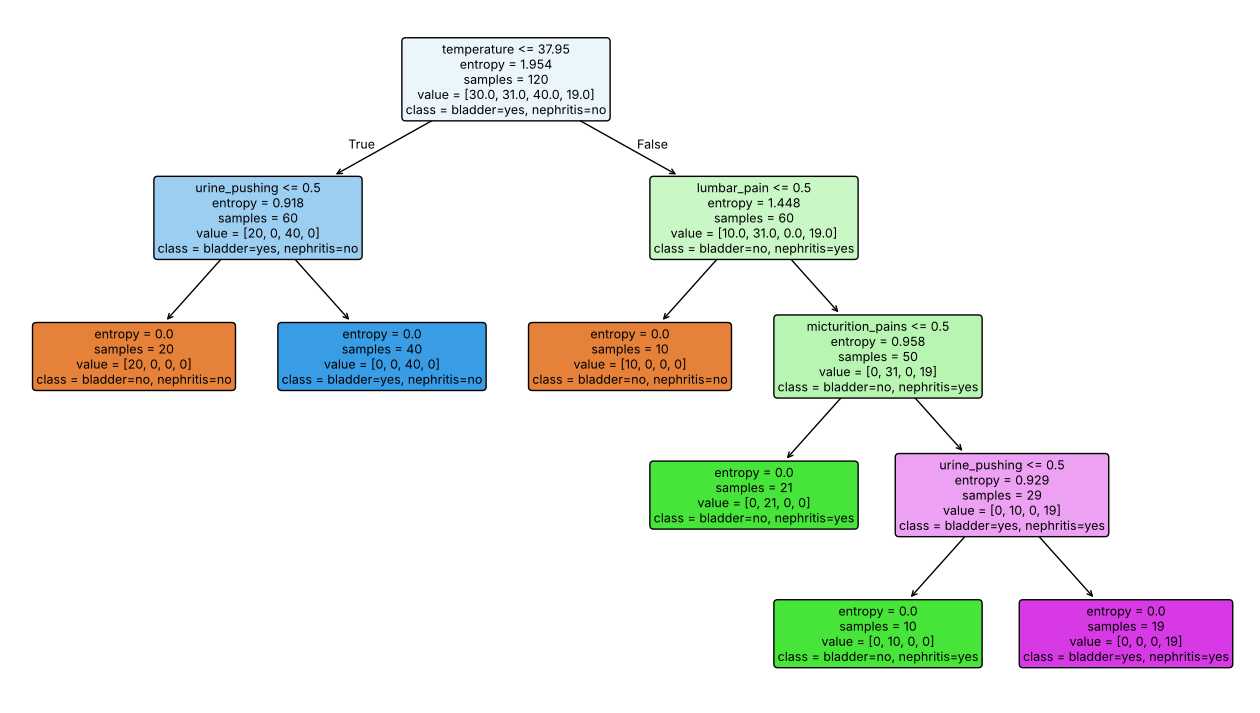

In [3]:
tree_model = DecisionTreeClassifier(criterion="entropy", random_state=0)
tree_model.fit(X_tree, y_tree)

print("Depth:", tree_model.get_depth())
print("Number of leaves:", tree_model.get_n_leaves())
print("Training accuracy:", tree_model.score(X_tree, y_tree))

plt.figure(figsize=(16, 9))
plot_tree(tree_model, feature_names=feature_cols, class_names=list(tree_model.classes_),
          filled=True, rounded=True, fontsize=9)
plt.show()

**Explanation:** We build the tree on the whole data set, like the question asks. We do not split the data into train and test here, because the goal is to read the rules, not to test the model on new patients. `criterion="entropy"` means the tree picks each split by information gain, and `random_state=0` makes sure we get the same tree every time. `plot_tree` draws the tree, and each box shows the split rule, how many patients are in the box, and the most common class. The tree we get has depth 4 and 6 leaves, and it gets all 120 patients right (training accuracy = 1.0). The first and most important split is on temperature at 37.95.

### (c) Convert the decision rules

In [4]:
def print_rules(model, feature_names):
    """Walk from the root to every leaf and print the path as an IF-THEN rule."""
    tree_ = model.tree_

    def walk(node, conditions):
        # A node is a leaf when it has no left child (sklearn stores -1).
        if tree_.children_left[node] == -1:
            class_name = model.classes_[np.argmax(tree_.value[node])]
            if len(conditions) == 0:
                print("ALWAYS THEN", class_name)
            else:
                print("IF " + " AND ".join(conditions) + " THEN " + class_name)
            return
        name = feature_names[tree_.feature[node]]
        threshold = tree_.threshold[node]
        walk(tree_.children_left[node], conditions + [f"{name} <= {threshold:.2f}"])
        walk(tree_.children_right[node], conditions + [f"{name} > {threshold:.2f}"])

    walk(0, [])

print_rules(tree_model, feature_cols)

IF temperature <= 37.95 AND urine_pushing <= 0.50 THEN bladder=no, nephritis=no
IF temperature <= 37.95 AND urine_pushing > 0.50 THEN bladder=yes, nephritis=no
IF temperature > 37.95 AND lumbar_pain <= 0.50 THEN bladder=no, nephritis=no
IF temperature > 37.95 AND lumbar_pain > 0.50 AND micturition_pains <= 0.50 THEN bladder=no, nephritis=yes
IF temperature > 37.95 AND lumbar_pain > 0.50 AND micturition_pains > 0.50 AND urine_pushing <= 0.50 THEN bladder=no, nephritis=yes
IF temperature > 37.95 AND lumbar_pain > 0.50 AND micturition_pains > 0.50 AND urine_pushing > 0.50 THEN bladder=yes, nephritis=yes


**Explanation:** This function follows the idea from the KDnuggets article in the question. It starts at the top of the tree and walks down to every leaf. When it goes left it adds the condition `feature <= threshold`, and when it goes right it adds `feature > threshold`. When it reaches a leaf, it prints all the conditions joined by AND, and then the class of that leaf. For the yes/no features the threshold is 0.5, so `<= 0.50` means "no" and `> 0.50` means "yes". In plain words, the 6 rules say this. If the temperature is 37.95 or lower, the patient has bladder inflammation only when they have urine pushing, and otherwise they have no disease. If the temperature is above 37.95 and there is no lumbar pain, the patient has no disease. If the temperature is above 37.95 and there is lumbar pain, the patient has nephritis. On top of that, if they also have micturition pains and urine pushing, they have both diseases. If either of those two symptoms is missing, they have nephritis only.

### (d) Cost-complexity pruning

In [5]:
# Get all the alpha values where the tree changes when we prune it.
path = tree_model.cost_complexity_pruning_path(X_tree, y_tree)
ccp_alphas = path.ccp_alphas

# The rows are sorted by temperature, so we shuffle inside the folds.
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

cv_accuracy = []
n_leaves = []
for alpha in ccp_alphas:
    pruned = DecisionTreeClassifier(criterion="entropy", random_state=0, ccp_alpha=alpha)
    scores = cross_val_score(pruned, X_tree, y_tree, cv=skf, scoring="accuracy")
    cv_accuracy.append(scores.mean())
    pruned.fit(X_tree, y_tree)
    n_leaves.append(pruned.get_n_leaves())

pruning_table = pd.DataFrame({"ccp_alpha": ccp_alphas,
                              "n_leaves": n_leaves,
                              "cv_accuracy": cv_accuracy})
print(pruning_table)

   ccp_alpha  n_leaves  cv_accuracy
0   0.000000         6     1.000000
1   0.199592         4     0.866667
2   0.325011         3     0.766667
3   0.459148         2     0.616667
4   0.770426         1     0.541667


**Explanation:** Cost-complexity pruning adds a penalty `ccp_alpha` for each leaf of the tree. A bigger alpha cuts off more branches, so the tree gets smaller. `cost_complexity_pruning_path` gives us the list of alpha values where the tree changes size. For each alpha, we use 5-fold cross-validation to measure the accuracy, and we also write down how many leaves the tree has. The rows in the file are sorted by temperature, so we shuffle the rows before making the folds. If we did not shuffle, some folds would only have low temperatures.

Best CV accuracy: 1.0
Chosen ccp_alpha: 0.0
Leaves after pruning: 6
Training accuracy after pruning: 1.0


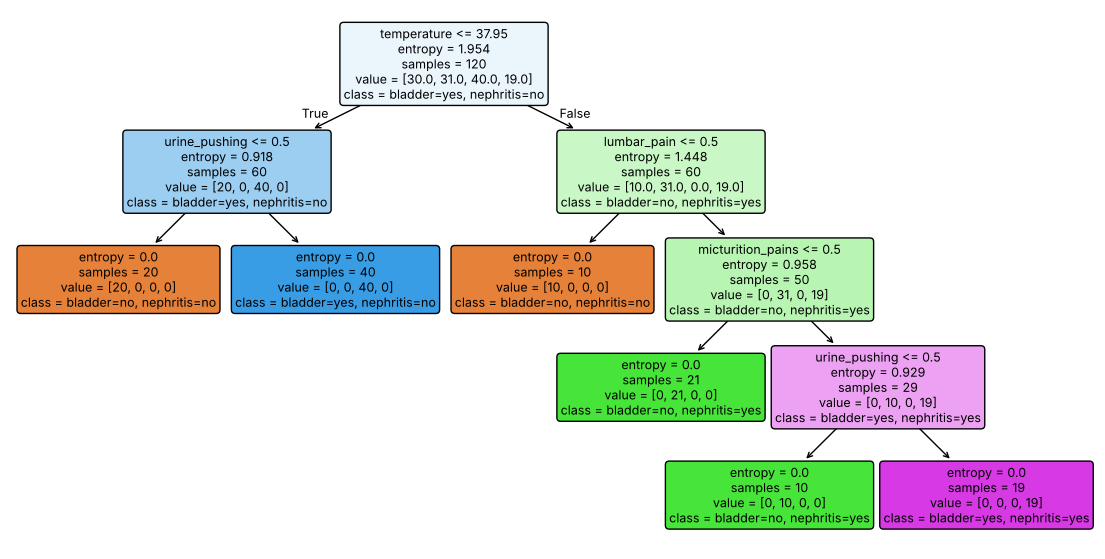

IF temperature <= 37.95 AND urine_pushing <= 0.50 THEN bladder=no, nephritis=no
IF temperature <= 37.95 AND urine_pushing > 0.50 THEN bladder=yes, nephritis=no
IF temperature > 37.95 AND lumbar_pain <= 0.50 THEN bladder=no, nephritis=no
IF temperature > 37.95 AND lumbar_pain > 0.50 AND micturition_pains <= 0.50 THEN bladder=no, nephritis=yes
IF temperature > 37.95 AND lumbar_pain > 0.50 AND micturition_pains > 0.50 AND urine_pushing <= 0.50 THEN bladder=no, nephritis=yes
IF temperature > 37.95 AND lumbar_pain > 0.50 AND micturition_pains > 0.50 AND urine_pushing > 0.50 THEN bladder=yes, nephritis=yes


In [6]:
# Pick the LARGEST alpha that still has the best CV accuracy.
# A larger alpha means more pruning, so this gives the smallest tree with the best accuracy.
best_accuracy = max(cv_accuracy)
best_alpha = 0
for alpha, acc in zip(ccp_alphas, cv_accuracy):
    if acc >= best_accuracy - 1e-9:
        best_alpha = alpha

print("Best CV accuracy:", best_accuracy)
print("Chosen ccp_alpha:", best_alpha)

pruned_tree = DecisionTreeClassifier(criterion="entropy", random_state=0, ccp_alpha=best_alpha)
pruned_tree.fit(X_tree, y_tree)
print("Leaves after pruning:", pruned_tree.get_n_leaves())
print("Training accuracy after pruning:", pruned_tree.score(X_tree, y_tree))

plt.figure(figsize=(14, 7))
plot_tree(pruned_tree, feature_names=feature_cols, class_names=list(pruned_tree.classes_),
          filled=True, rounded=True, fontsize=9)
plt.show()

print_rules(pruned_tree, feature_cols)

**Explanation:** We want the smallest tree that is still as accurate as possible, so out of all the alphas with the best CV accuracy, we pick the largest one. Then we train that tree on all the data, plot it, and print its rules with the function from part (c). The best CV accuracy is 1.0, and only `ccp_alpha = 0` reaches it. Every bigger alpha removes a split we need, and the CV accuracy drops (6 leaves: 1.000, 4 leaves: 0.867, 3 leaves: 0.767, 2 leaves: 0.617, 1 leaf: 0.542). This means pruning does not remove anything, and the tree from (b) is already the minimal tree that keeps full accuracy. Its 6 rules are short and easy to read, with at most 4 conditions each, and temperature is always checked first, so the rules are highly interpretable.

In [7]:
# For comparison: the next tree on the pruning path (one step more pruning).
smaller_tree = DecisionTreeClassifier(criterion="entropy", random_state=0, ccp_alpha=ccp_alphas[1])
smaller_tree.fit(X_tree, y_tree)
print("ccp_alpha:", ccp_alphas[1])
print("Leaves:", smaller_tree.get_n_leaves())
print("Training accuracy:", smaller_tree.score(X_tree, y_tree))
print_rules(smaller_tree, feature_cols)

ccp_alpha: 0.1995920879638124
Leaves: 4
Training accuracy: 0.8416666666666667
IF temperature <= 37.95 AND urine_pushing <= 0.50 THEN bladder=no, nephritis=no
IF temperature <= 37.95 AND urine_pushing > 0.50 THEN bladder=yes, nephritis=no
IF temperature > 37.95 AND lumbar_pain <= 0.50 THEN bladder=no, nephritis=no
IF temperature > 37.95 AND lumbar_pain > 0.50 THEN bladder=no, nephritis=yes


**Explanation:** To show why we keep the 6-leaf tree, we also look at the next smaller tree on the pruning path (`ccp_alpha` = 0.1996). This tree has only 4 leaves, but its training accuracy drops to 0.842. It removes the `micturition_pains` and `urine_pushing` splits for patients with high temperature, so no rule can predict "both diseases" anymore. All 19 patients who have both diseases would now be called "nephritis only". Saving 2 rules is not worth losing a whole class, so the 6-leaf tree is the best choice.

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [8]:
# Column names come from the "@attribute" lines in communities.names.
crime_columns = [
    "state", "county", "community", "communityname", "fold", "population", "householdsize",
    "racepctblack", "racePctWhite", "racePctAsian", "racePctHisp", "agePct12t21", "agePct12t29",
    "agePct16t24", "agePct65up", "numbUrban", "pctUrban", "medIncome", "pctWWage", "pctWFarmSelf",
    "pctWInvInc", "pctWSocSec", "pctWPubAsst", "pctWRetire", "medFamInc", "perCapInc",
    "whitePerCap", "blackPerCap", "indianPerCap", "AsianPerCap", "OtherPerCap", "HispPerCap",
    "NumUnderPov", "PctPopUnderPov", "PctLess9thGrade", "PctNotHSGrad", "PctBSorMore",
    "PctUnemployed", "PctEmploy", "PctEmplManu", "PctEmplProfServ", "PctOccupManu",
    "PctOccupMgmtProf", "MalePctDivorce", "MalePctNevMarr", "FemalePctDiv", "TotalPctDiv",
    "PersPerFam", "PctFam2Par", "PctKids2Par", "PctYoungKids2Par", "PctTeen2Par",
    "PctWorkMomYoungKids", "PctWorkMom", "NumIlleg", "PctIlleg", "NumImmig", "PctImmigRecent",
    "PctImmigRec5", "PctImmigRec8", "PctImmigRec10", "PctRecentImmig", "PctRecImmig5",
    "PctRecImmig8", "PctRecImmig10", "PctSpeakEnglOnly", "PctNotSpeakEnglWell",
    "PctLargHouseFam", "PctLargHouseOccup", "PersPerOccupHous", "PersPerOwnOccHous",
    "PersPerRentOccHous", "PctPersOwnOccup", "PctPersDenseHous", "PctHousLess3BR", "MedNumBR",
    "HousVacant", "PctHousOccup", "PctHousOwnOcc", "PctVacantBoarded", "PctVacMore6Mos",
    "MedYrHousBuilt", "PctHousNoPhone", "PctWOFullPlumb", "OwnOccLowQuart", "OwnOccMedVal",
    "OwnOccHiQuart", "RentLowQ", "RentMedian", "RentHighQ", "MedRent", "MedRentPctHousInc",
    "MedOwnCostPctInc", "MedOwnCostPctIncNoMtg", "NumInShelters", "NumStreet", "PctForeignBorn",
    "PctBornSameState", "PctSameHouse85", "PctSameCity85", "PctSameState85", "LemasSwornFT",
    "LemasSwFTPerPop", "LemasSwFTFieldOps", "LemasSwFTFieldPerPop", "LemasTotalReq",
    "LemasTotReqPerPop", "PolicReqPerOffic", "PolicPerPop", "RacialMatchCommPol", "PctPolicWhite",
    "PctPolicBlack", "PctPolicHisp", "PctPolicAsian", "PctPolicMinor", "OfficAssgnDrugUnits",
    "NumKindsDrugsSeiz", "PolicAveOTWorked", "LandArea", "PopDens", "PctUsePubTrans",
    "PolicCars", "PolicOperBudg", "LemasPctPolicOnPatr", "LemasGangUnitDeploy",
    "LemasPctOfficDrugUn", "PolicBudgPerPop", "ViolentCrimesPerPop"]

# Missing values are written as "?" in the file.
crime = pd.read_csv("../data/communities.data", header=None, names=crime_columns, na_values="?")
print(crime.shape)

# First 1495 rows are training data, the rest are test data.
train = crime.iloc[:1495]
test = crime.iloc[1495:]
print("Train:", train.shape, " Test:", test.shape)

(1994, 128)
Train: (1495, 128)  Test: (499, 128)


**Explanation:** We downloaded the data from the UCI link and saved it as `../data/communities.data`. The file has no header row, so we copy the 128 column names from the `@attribute` lines in `communities.names`. Missing values are written as `?` in the file, so `na_values="?"` turns them into `NaN`. The question says to use the first 1495 rows for training and the rest for testing. `iloc[:1495]` takes rows 0 to 1494, which is exactly 1495 rows, and the test set gets the other 499 rows.

### (b) Missing values

In [9]:
# The data description says these 5 columns are not predictive, so we drop them.
non_predictive = ["state", "county", "community", "communityname", "fold"]
target = "ViolentCrimesPerPop"

X_train_raw = train.drop(columns=non_predictive + [target])
y_train = train[target]
X_test_raw = test.drop(columns=non_predictive + [target])
y_test = test[target]

missing_counts = X_train_raw.isnull().sum() + X_test_raw.isnull().sum()
print("Features with missing values:")
print(missing_counts[missing_counts > 0])
print("Target missing:", y_train.isnull().sum() + y_test.isnull().sum())

# Median imputation. The medians are learned from the training set only,
# then the same medians are used to fill the test set.
imputer = SimpleImputer(strategy="median")
X_train = pd.DataFrame(imputer.fit_transform(X_train_raw), columns=X_train_raw.columns)
X_test = pd.DataFrame(imputer.transform(X_test_raw), columns=X_test_raw.columns)

print("Missing after imputation:", X_train.isnull().sum().sum() + X_test.isnull().sum().sum())
print("Number of features:", X_train.shape[1])

# The whole (imputed) data set, used for the plots in (c)-(e).
X_all = pd.concat([X_train, X_test], ignore_index=True)
y_all = pd.concat([y_train, y_test], ignore_index=True)

Features with missing values:
OtherPerCap                1
LemasSwornFT            1675
LemasSwFTPerPop         1675
LemasSwFTFieldOps       1675
LemasSwFTFieldPerPop    1675
LemasTotalReq           1675
LemasTotReqPerPop       1675
PolicReqPerOffic        1675
PolicPerPop             1675
RacialMatchCommPol      1675
PctPolicWhite           1675
PctPolicBlack           1675
PctPolicHisp            1675
PctPolicAsian           1675
PctPolicMinor           1675
OfficAssgnDrugUnits     1675
NumKindsDrugsSeiz       1675
PolicAveOTWorked        1675
PolicCars               1675
PolicOperBudg           1675
LemasPctPolicOnPatr     1675
LemasGangUnitDeploy     1675
PolicBudgPerPop         1675
dtype: int64
Target missing: 0
Missing after imputation: 0
Number of features: 122


**Explanation:** The data description says `state`, `county`, `community`, `communityname` and `fold` are not useful for prediction, so we drop them. We also take out `ViolentCrimesPerPop`, because it is the target we want to predict. This leaves 122 features. To fill in the missing values, we use the median of each column. We pick the median because very large or very small values do not change it as much as they change the mean. We find the medians using only the training set and then use them to fill both sets, so no information from the test set leaks into training. Before filling, 23 features had missing values. `OtherPerCap` was missing only 1 value, and the other 22 are police features, which are each missing in 1675 of the 1994 rows. The target has no missing values, and after filling there are no missing values left.

### (c) Plot a correlation matrix

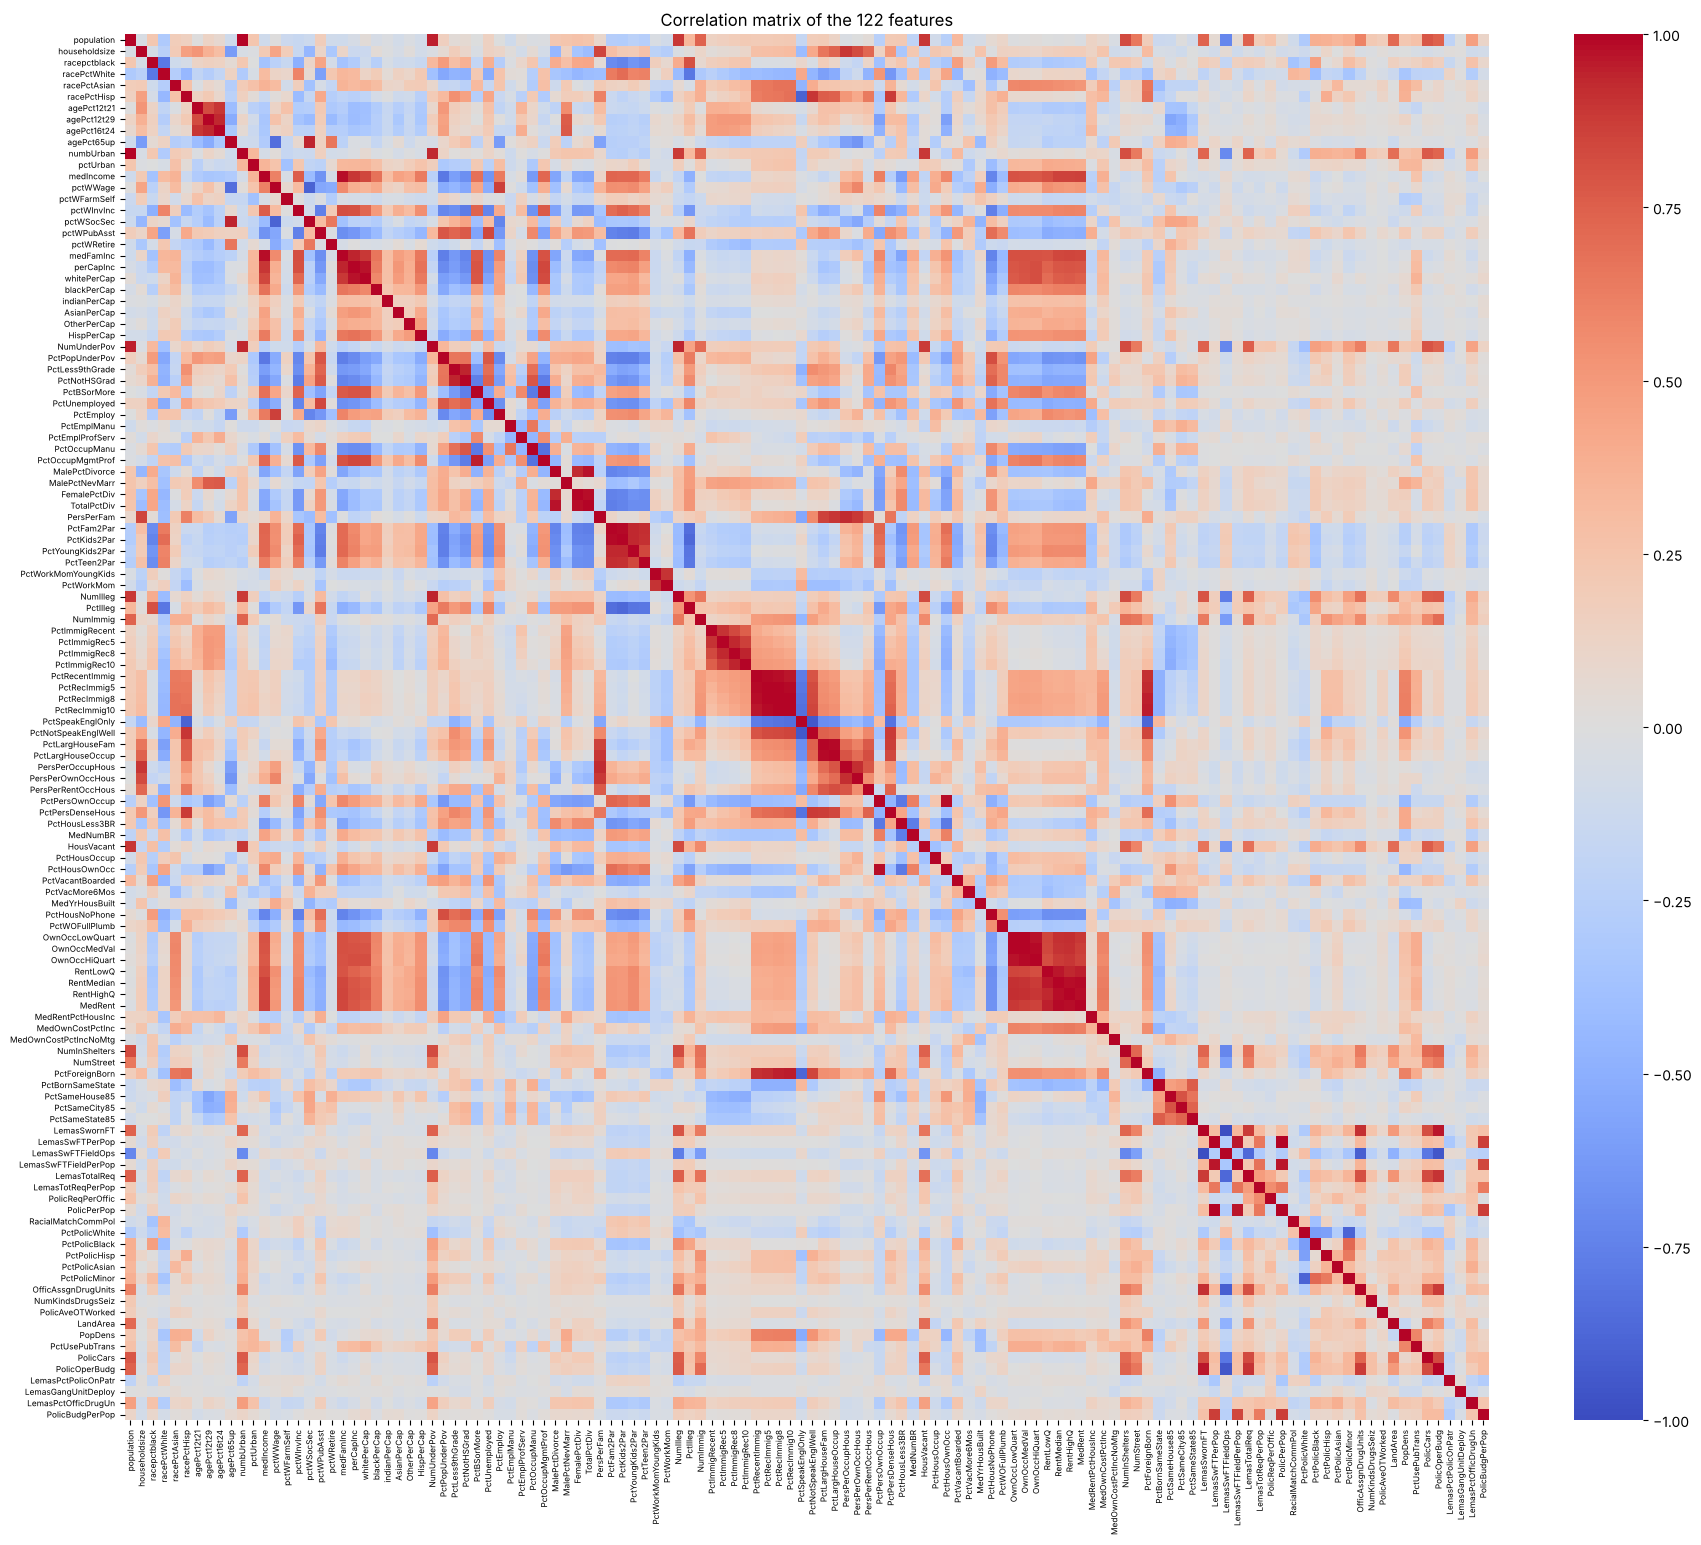

In [10]:
corr_matrix = X_all.corr()

plt.figure(figsize=(22, 18))
sns.heatmap(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1,
            xticklabels=True, yticklabels=True)
plt.xticks(fontsize=6)
plt.yticks(fontsize=6)
plt.title("Correlation matrix of the 122 features")
plt.show()

**Explanation:** `X_all.corr()` finds the correlation between every pair of the 122 features, and the heat map shows it with colors. Red means the two features go up together, blue means one goes up when the other goes down, and white means there is almost no link. The diagonal is always 1, because each feature matches itself perfectly. We use a small font so that all 122 names fit. The plot shows that some features are very strongly linked, for example `medIncome` and `medFamInc` (0.98) or `PctRecImmig5` and `PctRecImmig10` (0.99). This means many features carry almost the same information.

### (d) Calculate the Coefficient of Variation CV

In [11]:
# CV = sample standard deviation / sample mean
means = X_all.mean()
stds = X_all.std()          # pandas uses ddof=1, which is the sample standard deviation
print("Any feature with mean 0?", (means == 0).any())

cv_values = stds / means
cv_table = pd.DataFrame({"mean": means, "std": stds, "CV": cv_values})
cv_table = cv_table.sort_values("CV", ascending=False)
pd.set_option("display.max_rows", 200)
cv_table

Any feature with mean 0? False


,mean,std,CV
PctPolicAsian,0.018375,0.100105,5.447835
NumStreet,0.022778,0.100400,4.407702
NumInShelters,0.029438,0.102607,3.485481
NumIlleg,0.036294,0.108671,2.994196
NumImmig,0.030060,0.087189,2.900497
LemasPctOfficDrugUn,0.094052,0.240328,2.555266
NumUnderPov,0.055507,0.127941,2.304970
population,0.057593,0.126906,2.203503
LemasSwornFT,0.027944,0.058143,2.080712
numbUrban,0.064072,0.128256,2.001744


**Explanation:** The coefficient of variation is CV = s / m, where s is the sample standard deviation and m is the sample mean. `pandas.std()` uses `ddof=1`, which gives the sample standard deviation. We first check that no feature has a mean of 0, because then we would be dividing by zero, and none of them do. A high CV means the feature changes a lot compared to its average size. We compute CV on the whole data set after filling the missing values, because the question asks about the features of the data set.

### (e) Scatter plots and box plots for highest CV features

11 features with highest CV:
['PctPolicAsian', 'NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'population', 'LemasSwornFT', 'numbUrban', 'HousVacant']


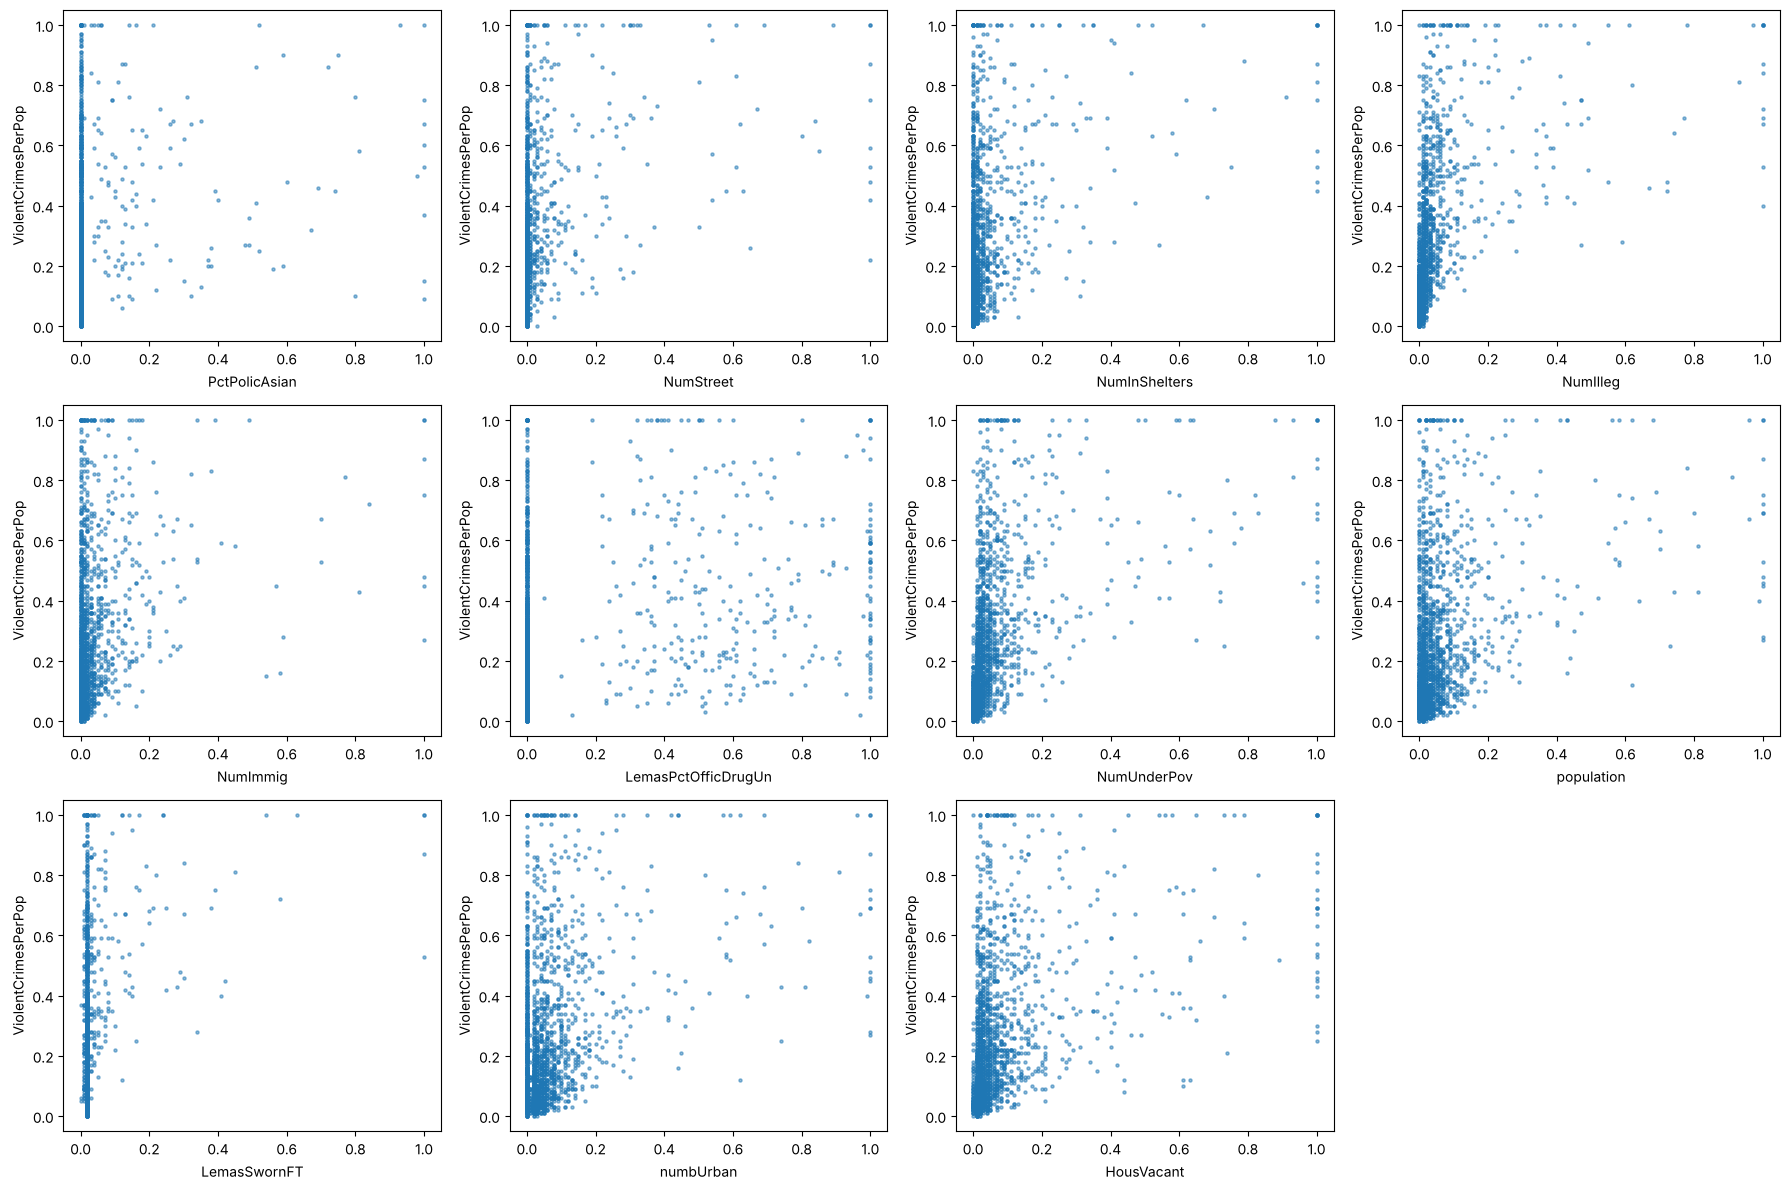

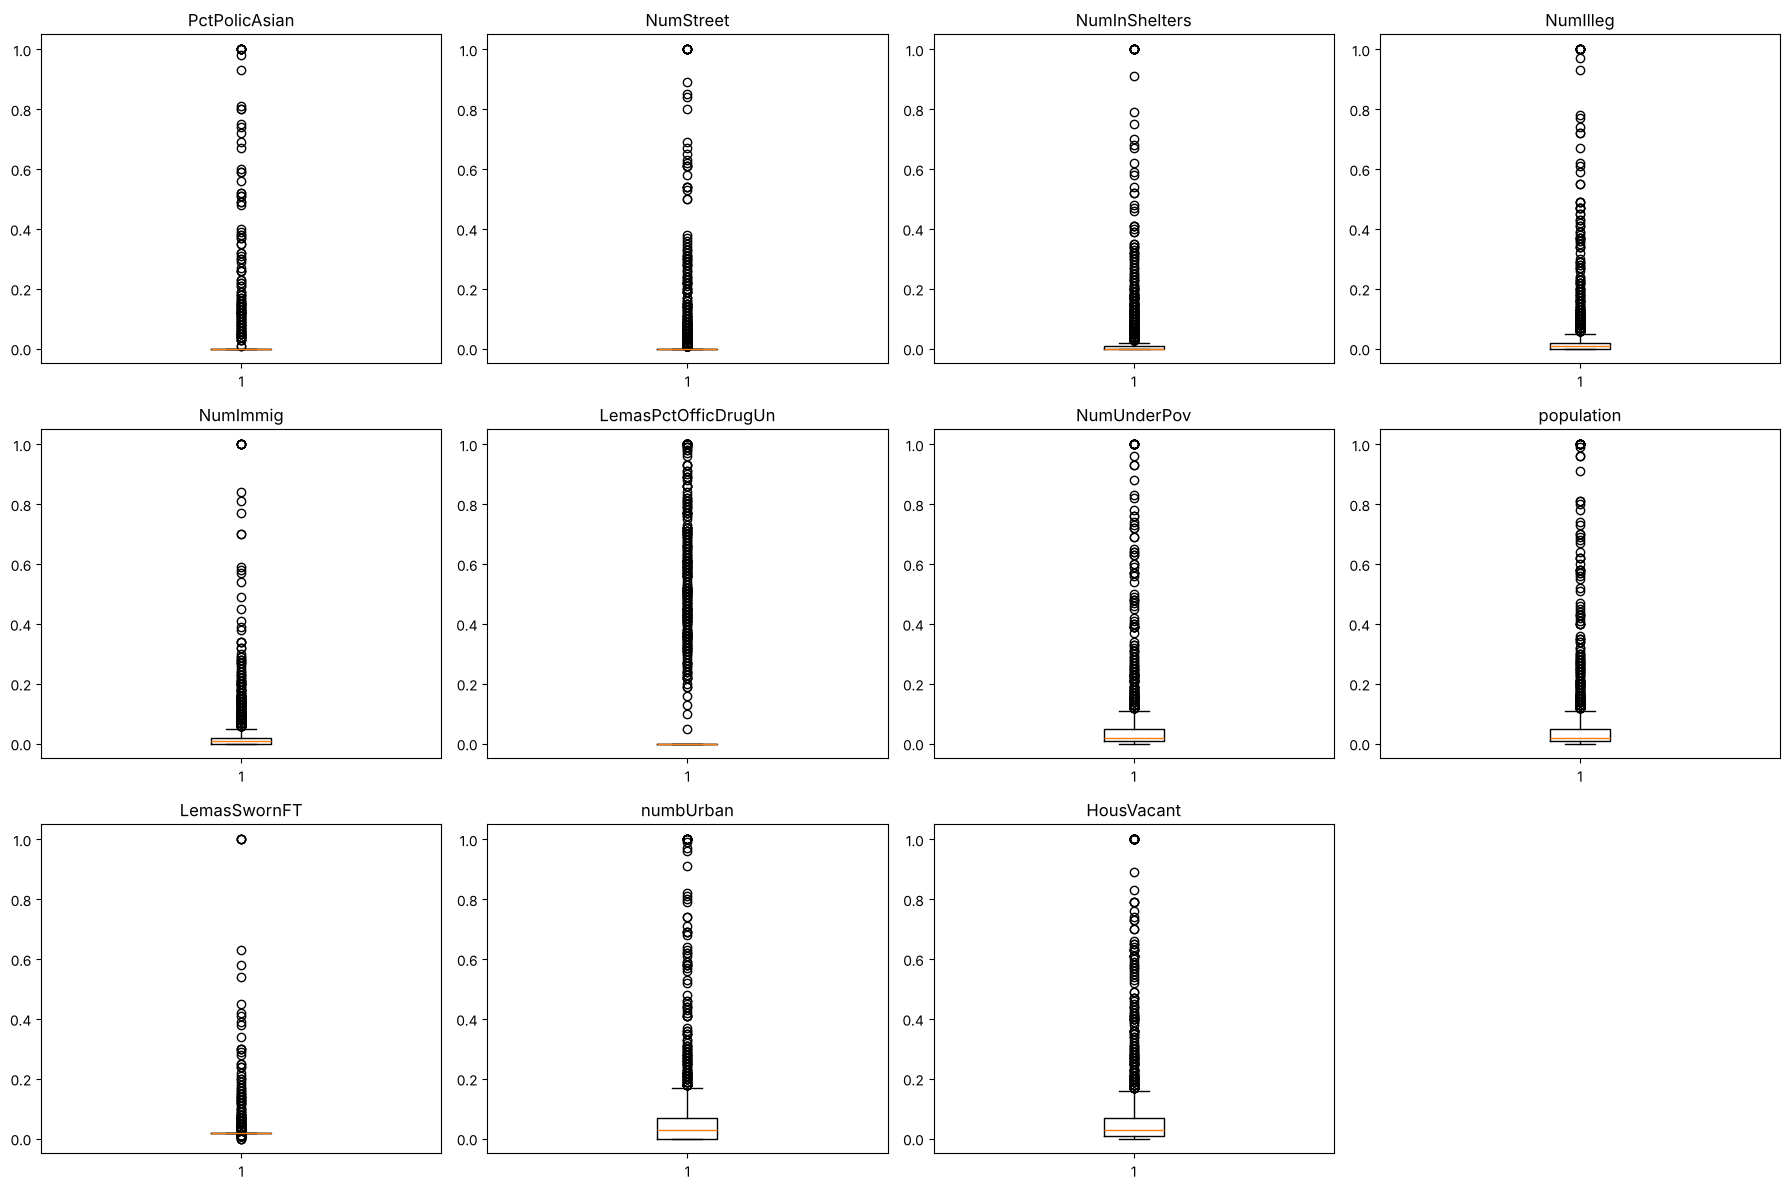

In [12]:
num_features = int(np.floor(np.sqrt(128)))
top_features = list(cv_table.index[:num_features])
print(num_features, "features with highest CV:")
print(top_features)

# Scatter plot of each feature against the target
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()
for i, feature in enumerate(top_features):
    axes[i].scatter(X_all[feature], y_all, s=5, alpha=0.5)
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel(target)
axes[-1].axis("off")      # 11 plots in a 12-slot grid, hide the empty one
plt.tight_layout()
plt.show()

# Box plot of each feature
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()
for i, feature in enumerate(top_features):
    axes[i].boxplot(X_all[feature])
    axes[i].set_title(feature)
axes[-1].axis("off")
plt.tight_layout()
plt.show()

**Explanation:** Since floor(sqrt(128)) = floor(11.31) = 11, we take the 11 features with the highest CV. These are `PctPolicAsian`, `NumStreet`, `NumInShelters`, `NumIlleg`, `NumImmig`, `LemasPctOfficDrugUn`, `NumUnderPov`, `population`, `LemasSwornFT`, `numbUrban` and `HousVacant`. The first set of plots shows each feature against the target `ViolentCrimesPerPop`. The second set shows a box plot for each feature, with the median, the middle 50% of the data (the box), and the outliers (the dots). We cannot decide if these features are significant just by looking at the scatter plots. Most points are packed near 0 on the x-axis, and for those points the target goes all the way from 0 to 1. A few features, like `NumIlleg` and `NumUnderPov`, show a weak upward trend, but the points are very spread out. A scatter plot also shows only one feature at a time, so it cannot show how a feature works together with the other features, and many features are strongly related (see part c). To call a feature significant, we need a model and a statistical test, like a p-value, not just a picture. The box plots show that these features are very skewed and have many outliers, which is why their CV is high. A high CV only tells us that a feature changes a lot, not that it predicts crime well. Also, three of these features (`PctPolicAsian`, `LemasPctOfficDrugUn` and `LemasSwornFT`) are police features. About 84% of their values were missing and were filled with the same median, which is why their scatter plots show a tall line of points at one x value. So part of their high CV comes from the filling, not from the real data.

### (f) Fit a linear model

In [13]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_test_mse = mean_squared_error(y_test, linear_model.predict(X_test))
print("Linear regression test MSE:", linear_test_mse)

Linear regression test MSE: 0.017966215426067328


**Explanation:** `LinearRegression` fits a least squares model on all 122 training features. We then predict the test set and measure the test error with the mean squared error (MSE), which is the average of (true value − predicted value)². The test MSE is 0.01797.

### (g) Fit a ridge regression model

In [14]:
# The same 10 folds are used for every model in (g)-(j).
kf = KFold(n_splits=10, shuffle=True, random_state=0)

ridge_alphas = np.logspace(-4, 4, 100)
ridge_model = RidgeCV(alphas=ridge_alphas, cv=kf, scoring="neg_mean_squared_error")
ridge_model.fit(X_train, y_train)

ridge_test_mse = mean_squared_error(y_test, ridge_model.predict(X_test))
print("Chosen lambda:", ridge_model.alpha_)
print("Ridge test MSE:", ridge_test_mse)

Chosen lambda: 2.310129700083163
Ridge test MSE: 0.017516249302564884


**Explanation:** Ridge regression adds a penalty of λ times the sum of the squared coefficients. This makes the coefficients smaller, which helps when the features are strongly related, like they are here. In sklearn, λ is called `alpha`. We try 100 λ values from 0.0001 to 10000, spread out evenly on a log scale, and use 10-fold cross-validation to pick the one with the lowest CV MSE. The folds are shuffled with a fixed seed, so we get the same result every time. We make these folds (`kf`) once and use the same ones for ridge, LASSO, PCR and XGBoost, so the models are compared fairly. The chosen λ is 2.31, which is inside the range we searched and not at the edge. The test MSE is 0.01752, a little lower than least squares.

### (h) Fit a LASSO model

In [15]:
# LASSO on the features as they are (already normalized to 0-1)
lasso_model = LassoCV(cv=kf, max_iter=100000, random_state=0)
lasso_model.fit(X_train, y_train)

lasso_test_mse = mean_squared_error(y_test, lasso_model.predict(X_test))
lasso_selected = list(X_train.columns[lasso_model.coef_ != 0])
print("Chosen lambda:", lasso_model.alpha_)
print("LASSO test MSE:", lasso_test_mse)
print(len(lasso_selected), "variables selected:")
print(lasso_selected)

Chosen lambda: 8.786112483379066e-05
LASSO test MSE: 0.017681738664495253
77 variables selected:
['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'agePct65up', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'medFamInc', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctBSorMore', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PersPerOwnOccHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOw

**Explanation:** LASSO adds a penalty of λ times the sum of the absolute values of the coefficients. This penalty can push some coefficients all the way to 0, so LASSO also chooses which variables to keep. `LassoCV` makes its own list of 100 λ values and picks the best one with 10-fold cross-validation. A variable counts as "selected" if its coefficient is not 0. We set `max_iter` high so the solver has enough steps to finish. The chosen λ is 0.0000879, which is inside the search range. The test MSE is 0.01768, and the model keeps 77 of the 122 variables (the full list is printed above).

In [16]:
# LASSO on standardized features (mean 0, std 1).
# The scaler learns mean and std from the training set only.
scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)

lasso_std_model = LassoCV(cv=kf, max_iter=100000, random_state=0)
lasso_std_model.fit(X_train_std, y_train)

lasso_std_test_mse = mean_squared_error(y_test, lasso_std_model.predict(X_test_std))
lasso_std_selected = list(X_train.columns[lasso_std_model.coef_ != 0])
print("Chosen lambda:", lasso_std_model.alpha_)
print("Standardized LASSO test MSE:", lasso_std_test_mse)
print(len(lasso_std_selected), "variables selected:")
print(lasso_std_selected)

print()
print("Test MSE, original features:    ", lasso_test_mse)
print("Test MSE, standardized features:", lasso_std_test_mse)

Chosen lambda: 0.0006189604623293166
Standardized LASSO test MSE: 0.017726991419780687
76 variables selected:
['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRecent', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PersPerOwnOccHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc

**Explanation:** Now we standardize every feature so it has mean 0 and standard deviation 1, and then run LASSO again. The scaler learns the mean and standard deviation from the training set only and then uses them on the test set. Standardizing matters for LASSO because the penalty treats all coefficients the same way. A feature with a small spread needs a big coefficient, so it gets punished more, and standardizing puts all features on the same scale. With the original features, LASSO picks λ = 0.0000879, keeps 77 variables, and has a test MSE of 0.01768. With standardized features, it picks λ = 0.000619, keeps 76 variables, and has a test MSE of 0.01773. The two test errors are almost the same, with a difference of only about 0.00005. The chosen variables are also very similar, and 74 variables are kept by both models. Only `agePct65up`, `medFamInc` and `PctBSorMore` are kept just by the first model, and only `PctImmigRecent` and `OfficAssgnDrugUnits` are kept just by the second. This makes sense, because `communities.names` says all features are already normalized to the range 0 to 1, so standardizing does not change their scale very much. The two λ values are different because the coefficients are on a different scale after standardizing, so we cannot compare the λ values directly.

### (i) Fit a PCR model

Best M: 95
CV MSE at best M: 0.019530508072231424


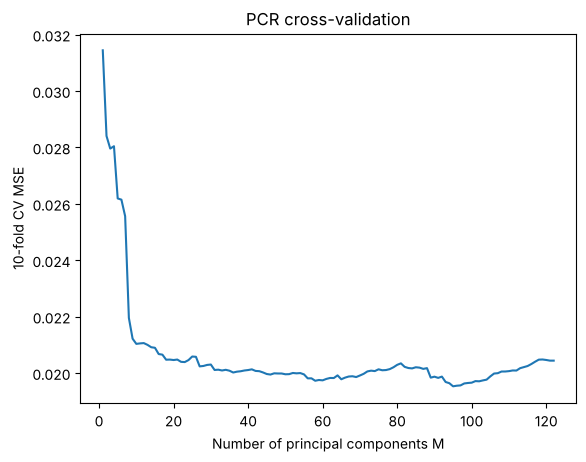

PCR test MSE: 0.01829634536770982


In [17]:
# Try every number of components M and keep the one with the lowest CV error.
# Each feature is scaled to standard deviation one before PCA.
max_m = X_train.shape[1]
pcr_cv_mse = []
for m in range(1, max_m + 1):
    pcr = make_pipeline(StandardScaler(), PCA(n_components=m), LinearRegression())
    scores = cross_val_score(pcr, X_train, y_train, cv=kf, scoring="neg_mean_squared_error")
    pcr_cv_mse.append(-scores.mean())

best_m = int(np.argmin(pcr_cv_mse)) + 1     # +1 because the list starts at M = 1
print("Best M:", best_m)
print("CV MSE at best M:", min(pcr_cv_mse))

plt.plot(range(1, max_m + 1), pcr_cv_mse)
plt.xlabel("Number of principal components M")
plt.ylabel("10-fold CV MSE")
plt.title("PCR cross-validation")
plt.show()

pcr_model = make_pipeline(StandardScaler(), PCA(n_components=best_m), LinearRegression())
pcr_model.fit(X_train, y_train)
pcr_test_mse = mean_squared_error(y_test, pcr_model.predict(X_test))
print("PCR test MSE:", pcr_test_mse)

**Explanation:** PCR (principal components regression) works in two steps. First, PCA turns the 122 features into M new features called principal components, which are not related to each other. Then a linear regression is fit on those M components. Before PCA, we scale each feature to have standard deviation 1. PCA looks for the directions with the most variance, so without scaling, a feature with a bigger spread would get more weight just because of its size. `make_pipeline` joins the steps together, so in each CV fold the scaling and PCA are learned only from that fold's training part. We try every M from 1 to 122 and pick the one with the lowest 10-fold CV MSE, and the plot shows the CV MSE for each M. The best M is 95, and the test MSE is 0.01830, which is a bit worse than least squares, ridge and LASSO on this test set.

### (j) Fit a boosting tree

In [18]:
# reg_alpha is the L1 penalty (the alpha in the question) on the leaf weights.
param_grid = {"reg_alpha": [0, 0.001, 0.01, 0.1, 0.5, 1, 5, 10]}

# Number of trees B = 1000, shrinkage = 0.01, each tree is a stump (d = 1).
# reg_lambda (the L2 penalty) is 1 by default. We set it to 0 so the only penalty is L1.
xgb_base = XGBRegressor(n_estimators=1000, learning_rate=0.01, max_depth=1,
                        reg_lambda=0, random_state=0)
xgb_search = GridSearchCV(xgb_base, param_grid, cv=kf, scoring="neg_mean_squared_error")
xgb_search.fit(X_train, y_train)

print("CV MSE for each alpha:")
for alpha, score in zip(param_grid["reg_alpha"], xgb_search.cv_results_["mean_test_score"]):
    print(f"  alpha = {alpha}: {-score:.5f}")
print("Best alpha:", xgb_search.best_params_["reg_alpha"])

xgb_test_mse = mean_squared_error(y_test, xgb_search.best_estimator_.predict(X_test))
print("XGBoost test MSE:", xgb_test_mse)

CV MSE for each alpha:
  alpha = 0: 0.01982
  alpha = 0.001: 0.01982
  alpha = 0.01: 0.01981
  alpha = 0.1: 0.01976
  alpha = 0.5: 0.01975
  alpha = 1: 0.01981
  alpha = 5: 0.02052
  alpha = 10: 0.02164
Best alpha: 0.5
XGBoost test MSE: 0.01661246443859222


**Explanation:** Boosting builds many small trees one after another, and each new tree tries to fix the mistakes left by the trees before it. In XGBoost, `reg_alpha` is the L1 penalty on the leaf values, which is the α in the question. A bigger α pushes the leaf values toward 0. XGBoost also has an L2 penalty called `reg_lambda`, which is 1 by default. We set it to 0 so that the model is a pure L1-penalized boosting tree and α is the only penalty we tune. We keep the other settings fixed: B = 1000 trees, a shrinkage (learning rate) of 0.01, and one split per tree (d = 1). A small shrinkage makes the model learn slowly, so it needs many trees. We use `GridSearchCV` with the same 10 folds to choose α from 0, 0.001, 0.01, 0.1, 0.5, 1, 5 and 10, and then we predict the test set with the best model. The best α is 0.5. The CV MSE is almost the same for α from 0 to 1 (about 0.0198), it is lowest at α = 0.5 (0.01975), and it gets clearly worse at α = 5 and 10. The test MSE is 0.01661, which is the lowest of all the models in this homework. For comparison, the test MSE is 0.01797 for least squares, 0.01752 for ridge, 0.01768 for LASSO, 0.01773 for standardized LASSO, and 0.01830 for PCR. These numbers came from scikit-learn 1.9.1 and XGBoost 3.4.1, and other versions may give slightly different XGBoost numbers.